In [2]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("kaggle_runs/car_train/results.csv")
df.head()

,epoch,time,train/box_loss,train/cls_loss,train/l1_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/l1_loss,lr/pg0,lr/pg1,lr/pg2
0,1,30.3511,1.59093,1.10985,0.00741,0.93816,0.85000,0.93422,0.52161,1.50639,0.59331,0.00918,0.000663,0.000663,0.000663
1,2,61.3704,1.46483,0.71207,0.00709,0.91835,0.84352,0.93734,0.49018,1.73528,0.67364,0.01115,0.001286,0.001286,0.001286
2,3,92.0555,1.60279,0.81311,0.00746,0.93202,0.91404,0.97063,0.57525,1.36146,0.48317,0.00896,0.001865,0.001865,0.001865
3,4,122.3830,1.46114,0.76378,0.00706,0.89607,0.86218,0.94633,0.48833,1.61492,0.66248,0.01057,0.001802,0.001802,0.001802
4,5,153.5020,1.56963,0.73706,0.00744,0.92601,0.93869,0.95276,0.55387,1.47726,0.65628,0.00948,0.001736,0.001736,0.001736


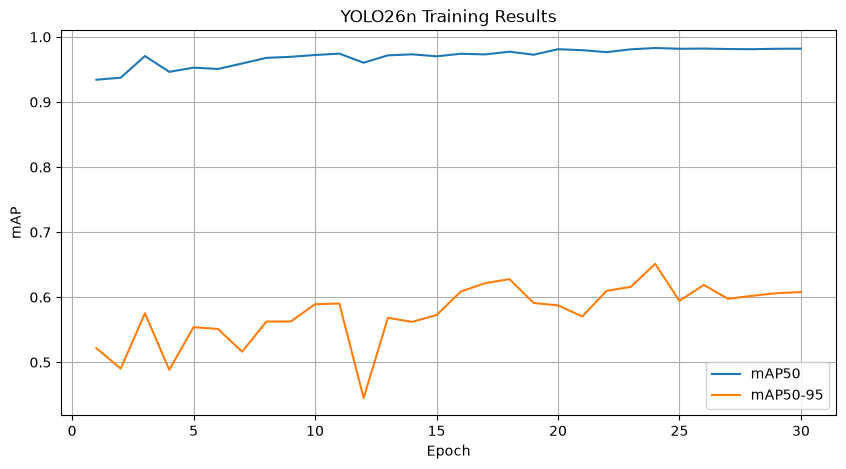

In [3]:
plt.figure(figsize=(10, 5))

plt.plot(df["epoch"], df["metrics/mAP50(B)"], label="mAP50")
plt.plot(df["epoch"], df["metrics/mAP50-95(B)"], label="mAP50-95")

plt.xlabel("Epoch")
plt.ylabel("mAP")
plt.title("YOLO26n Training Results")
plt.legend()
plt.grid(True)
plt.show()

# YOLO26n 기반 자동차 객체 탐지 모델 학습 및 성능 분석 보고서

**실험일:** 2026년 11월 6일  
**실험 유형:** 객체 탐지 모델 학습 및 검증  
**사용 모델:** YOLO26n  
**데이터 출처:** Kaggle 자동차 객체 탐지 데이터셋  
**실험 단계:** 교육용 실습 및 성능 검증

---

## 1. 실험 개요 및 목적

본 실험은 자동차 이미지 데이터셋을 활용하여 YOLO26n 객체 탐지 모델을 학습하고, 학습 과정에서 나타나는 성능 변화를 분석하는 것을 목적으로 한다.

객체 탐지는 이미지에 자동차가 존재하는지 판단하는 것뿐만 아니라, 자동차가 이미지의 어느 위치에 있는지 사각형으로 표시하는 작업이다.

이번 실험에서는 사전 학습된 YOLO26n 모델을 자동차 탐지 작업에 맞게 추가 학습하고, 총 30에포크 동안 기록된 성능 지표를 분석하였다.

주요 분석 목표는 다음과 같다.

1. 학습이 진행되면서 자동차 탐지 성능이 개선되는지 확인한다.
2. 정밀도, 재현율, mAP50, mAP50-95의 변화를 비교한다.
3. 가장 마지막에 학습한 모델과 가장 높은 검증 성능을 기록한 모델의 차이를 확인한다.
4. 실험 결과의 한계와 추가 검증이 필요한 부분을 파악한다.

## 2. 데이터 및 실험 환경

### 2.1. 데이터 구성

Kaggle에서 내려받은 자동차 객체 탐지 데이터셋을 사용하였다.

원본 데이터에는 이미지와 자동차 위치를 나타내는 좌표 정보가 별도로 제공되었다. 이를 YOLO 학습에 필요한 형식으로 변환하였다.

| 항목 | 내용 |
|---|---|
| 탐지 대상 | 자동차(Car) |
| 전체 학습용 원본 이미지 | 1,001장 |
| 학습 데이터 | 800장 |
| 검증 데이터 | 201장 |
| 객체 종류 | 1개 클래스(Car) |
| 정답 좌표 형식 | 원본 CSV의 xmin, ymin, xmax, ymax |
| 변환 후 좌표 형식 | YOLO의 정규화된 중심 좌표 및 너비·높이 |

YOLO 형식은 객체의 중심 위치와 크기를 이미지 전체 크기에 대한 비율로 표현하는 방식이다.

### 2.2. 데이터 전처리

학습을 위해 다음 과정을 수행하였다.

1. 이미지 파일과 정답 CSV의 파일명을 확인하였다.
2. CSV에 기록된 자동차 위치를 YOLO 형식으로 변환하였다.
3. 이미지와 정답 파일을 학습용 및 검증용으로 분리하였다.
4. 데이터 경로와 클래스 정보를 담은 `dataset.yaml`을 생성하였다.

학습과 검증 데이터는 무작위로 분할하였으며, 별도의 영상 단위 분리 과정은 적용하지 않았다.

### 2.3. 모델 및 학습 조건

| 항목 | 설정 |
|---|---|
| 모델 | YOLO26n |
| 초기 가중치 | 사전 학습된 `yolo26n.pt` |
| 학습 횟수 | 30에포크 |
| 입력 이미지 크기 | 320 × 320 |
| 배치 크기 | 4 |
| 학습 장치 | CPU |
| DataLoader 작업 프로세스 | 0 |
| 학습 시간 | 약 934초(15분 34초) |

이번 실험은 모델을 처음부터 무작위로 학습하는 방식이 아니라, 기존에 학습된 모델을 자동차 데이터에 맞게 추가 학습하는 방식으로 진행하였다.

## 3. 성능 평가 방법

### 3.1. 정밀도(Precision)

모델이 자동차라고 탐지한 결과 중 실제로 올바른 탐지가 얼마나 포함되어 있는지를 나타낸다.

정밀도가 높을수록 잘못된 탐지, 즉 오탐이 상대적으로 적다는 의미이다.

### 3.2. 재현율(Recall)

실제 존재하는 자동차 중 모델이 얼마나 찾아냈는지를 나타낸다.

재현율이 높을수록 실제 자동차를 놓치는 경우가 상대적으로 적다는 의미이다.

### 3.3. mAP50

예측한 사각형과 실제 정답 사각형이 얼마나 겹치는지를 나타내는 IoU를 0.5 이상으로 판단했을 때의 평균 정밀도(AP)이다.

이번 실험은 자동차 한 종류만 탐지하므로, mAP50은 자동차 클래스의 AP50에 해당한다.

### 3.4. mAP50-95

IoU 기준을 0.50부터 0.95까지 높여가며 계산한 AP를 평균한 지표이다.

mAP50보다 사각형 위치의 정확성을 더 엄격하게 평가한다.

따라서 mAP50은 높더라도 mAP50-95가 상대적으로 낮다면, 자동차를 찾아내는 능력에 비해 사각형 위치를 정밀하게 맞추는 능력에는 개선 여지가 있다고 해석할 수 있다.

## 4. 실험 결과

### 4.1. 주요 성능 변화

| 평가 지표 | 1에포크 | 30에포크 | 변화 |
|---|---:|---:|---:|
| 정밀도 | 93.82% | 97.41% | +3.59%p |
| 재현율 | 85.00% | 94.02% | +9.02%p |
| mAP50 | 93.42% | 98.19% | +4.77%p |
| mAP50-95 | 52.16% | 60.79% | +8.63%p |

30에포크 학습 후 모든 주요 평가 지표가 1에포크보다 높아졌다.

특히 재현율은 85.00%에서 94.02%로 증가하였다. 이는 학습이 진행되면서 실제 자동차를 찾아내는 성능이 개선되었음을 보여준다.

정밀도 역시 97.41%까지 상승하여 검증 데이터에서 잘못된 탐지를 줄이는 성능도 개선된 것으로 나타났다.

### 4.2. 에포크별 성능 변화

**[여기에 Jupyter에서 생성한 mAP50 및 mAP50-95 변화 그래프 배치]**

mAP50은 초기부터 90% 이상의 높은 수준을 보였으며, 학습이 진행되면서 점진적으로 개선되었다.

반면 mAP50-95는 에포크마다 상승과 하락을 반복하였다.

주요 시점의 결과는 다음과 같다.

| 에포크 | mAP50 | mAP50-95 |
|---|---:|---:|
| 1 | 93.42% | 52.16% |
| 5 | 95.28% | 55.39% |
| 10 | 97.22% | 58.92% |
| 16 | 97.41% | 60.87% |
| 20 | 98.11% | 58.74% |
| 24 | 98.30% | 65.12% |
| 30 | 98.19% | 60.79% |

이 결과는 학습 횟수가 증가한다고 해서 모든 평가 지표가 매번 개선되는 것은 아니라는 점을 보여준다.

특히 24에포크에서 mAP50-95가 최고치를 기록한 이후, 마지막 에포크에서는 해당 지표가 다소 낮아졌다.

### 4.3. 학습 손실 변화

손실(Loss)은 모델의 예측과 정답 사이의 차이를 학습 과정에서 계산한 값이다. 일반적으로 같은 조건에서 손실이 감소하는 것은 학습이 진행되고 있음을 보여준다.

| 손실 지표 | 1에포크 | 30에포크 |
|---|---:|---:|
| Train Box Loss | 1.59093 | 0.95060 |
| Train Class Loss | 1.10985 | 0.30721 |
| Validation Box Loss | 1.50639 | 1.24380 |
| Validation Class Loss | 0.59331 | 0.42704 |

학습 데이터의 Box Loss와 Class Loss는 전반적으로 감소하였다.

이는 모델이 학습 데이터에서 자동차의 위치와 종류를 예측하는 과정에서 오차를 줄여갔다는 의미이다.

검증 손실 역시 초기보다 낮아졌지만, 학습 과정에서 지속적으로 감소하지는 않고 변동하는 모습을 보였다.

따라서 학습 자체는 진행되었으나, 검증 성능이 매 에포크마다 안정적으로 개선된 것은 아니라고 판단된다.

## 5. 최적 모델 분석

### 5.1. 최고 성능 기록

30에포크 중 mAP50-95가 가장 높았던 시점은 **24에포크**이다.

| 항목 | 24에포크 | 30에포크 |
|---|---:|---:|
| 정밀도 | 97.10% | 97.41% |
| 재현율 | 94.17% | 94.02% |
| mAP50 | 98.30% | 98.19% |
| mAP50-95 | 65.12% | 60.79% |

마지막 에포크에서는 정밀도가 약간 더 높았지만, mAP50과 mAP50-95는 24에포크가 더 높았다.

특히 mAP50-95는 24에포크가 마지막 에포크보다 약 4.33%p 높았다.

### 5.2. 결과 해석

이번 결과는 마지막까지 학습한 모델이 반드시 가장 좋은 검증 성능을 나타내는 것은 아니라는 점을 보여준다.

모델을 선택할 때는 단순히 학습 횟수보다 검증 데이터에서 나타난 성능을 기준으로 판단해야 한다.

다만 `best.pt`가 실제로 어느 에포크에서 저장되었는지는 학습 프로그램의 모델 선택 기준과 저장 기록을 확인해야 확정할 수 있다.

## 6. 실험의 한계

### 6.1. 데이터 분할 방식의 한계

이번 실험에서는 원본 이미지를 무작위로 학습 데이터와 검증 데이터로 분리하였다.

하지만 원본 데이터에 동일한 영상에서 추출한 연속 프레임이 포함되어 있다면, 매우 유사한 이미지가 학습 데이터와 검증 데이터에 동시에 포함될 수 있다.

이 경우 모델이 완전히 새로운 환경의 자동차를 탐지하는 능력보다 검증 성능이 높게 측정될 가능성이 있다.

따라서 현재의 높은 mAP50을 실제 모든 환경에서 동일하게 얻을 수 있는 성능으로 해석해서는 안 된다.

### 6.2. 엄격한 위치 정확도의 한계

최종 mAP50은 98.19%였지만 mAP50-95는 60.79%였다.

이는 자동차 탐지 자체에서는 높은 성능을 보였으나, 예측 사각형이 실제 자동차의 위치와 더욱 정밀하게 일치해야 하는 조건에서는 성능이 낮아졌다는 의미이다.

다만 두 지표의 차이만으로 특정한 위치 오차의 원인을 확정할 수는 없다.

### 6.3. 일반화 성능 검증의 한계

이번 분석은 학습 과정에서 사용한 검증 데이터의 결과를 중심으로 진행하였다.

별도로 확보한 독립적인 테스트 데이터에 대한 정량 평가 결과는 포함하지 않았다.

따라서 새로운 촬영 장소, 조명, 자동차 크기 및 배경에서도 동일한 성능을 유지하는지는 추가 검증이 필요하다.

## 7. 최종 결론

본 실험에서는 Kaggle 자동차 객체 탐지 데이터셋을 활용하여 사전 학습된 YOLO26n 모델을 30에포크 동안 추가 학습하였다.

그 결과 정밀도 97.41%, 재현율 94.02%, mAP50 98.19%, mAP50-95 60.79%를 기록하였다.

학습 초기와 비교했을 때 모든 주요 평가 지표가 개선되었으며, 학습 손실도 전반적으로 감소하였다. 이를 통해 자동차 탐지 작업에 대한 추가 학습이 정상적으로 진행되었음을 확인할 수 있었다.

그러나 mAP50-95는 24에포크에서 최고치를 기록한 이후 하락하였으며, 데이터 분할 과정에서 유사한 영상 프레임이 학습·검증 데이터에 함께 포함되었을 가능성도 존재한다.

따라서 이번 결과는 **현재 검증 데이터에서 높은 자동차 탐지 성능을 확보한 교육용 실험 결과**로 평가할 수 있다. 다만 실제 환경에서의 활용 가능성을 판단하기 위해서는 영상 단위 데이터 분리와 독립적인 테스트 데이터에 대한 추가 평가가 필요하다.